<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab7_3_NaiveBayes_Peru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación Naive Bayes
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 75 minutos

Referencia: [documentación de Naive Bayes en scikit-learn](https://scikit-learn.org/stable/modules/naive_bayes.html)

---

### Objetivos de aprendizaje

1. Explicar el teorema de Bayes y cómo se usa para clasificación.
2. Describir el supuesto de independencia "naive" y por qué suele funcionar bien a pesar de ser irreal.
3. Distinguir entre Naive Bayes Gaussiano, Multinomial y Bernoulli.
4. Entrenar y evaluar un clasificador Naive Bayes en `scikit-learn`.
5. Comparar Naive Bayes con SVM y regresión logística en términos de velocidad y exactitud.

## 1. Repaso de Probabilidad

Antes de adentrarnos en el algoritmo, recordemos algunos conceptos clave de probabilidad.

### Probabilidad condicional

La probabilidad del evento $A$ dado que el evento $B$ ha ocurrido:

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}$$

**Ejemplo ambiental:** ¿Cuál es la probabilidad de que haya contaminación del aire ($A$) dado que estamos en temporada de incendios forestales en la Amazonia ($B$)?

### Prior, Verosimilitud (likelihood) y Posterior

- **Prior** $P(A)$: nuestra creencia sobre $A$ antes de ver datos (ej. "el 30% de los días en Lima hay mala calidad del aire")
- **Verosimilitud** $P(B \mid A)$: qué tan probable es observar $B$ si $A$ fuera cierto
- **Posterior** $P(A \mid B)$: nuestra creencia actualizada sobre $A$ después de observar $B$

## 2. El Teorema de Bayes

![Thomas Bayes 1701-1761](https://marvel-b1-cdn.bc0a.com/f00000000100045/www.elmhurst.edu/wp-content/uploads/2019/08/amazing-thomas-bayes-illustration.jpg)

El teorema de Bayes relaciona estas cantidades:

$$P(A \mid B) = \frac{P(B \mid A) \cdot P(A)}{P(B)}$$

En el contexto de la clasificación, queremos calcular la probabilidad de que un punto de datos $\mathbf{x}$ pertenezca a la clase $c$:

$$P(c \mid \mathbf{x}) = \frac{P(\mathbf{x} \mid c) \cdot P(c)}{P(\mathbf{x})}$$

donde:

| Término | Significado | Ejemplo |
|---|---|---|
| $P(c)$ | **Probabilidad a priori**: ¿Qué tan común es la clase $c$? | El 30% de la región es bosque |
| $P(\mathbf{x} \mid c)$ | **Probabilidad de verosimilitud**: Dada la clase $c$, ¿qué tan probables son estos valores de características? | ¿Qué valores de NDVI y elevación suelen tener los píxeles de bosque? |
| $P(\mathbf{x})$ | **Evidencia**: ¿Qué tan probables son estos valores de características en general? | Son los mismos para todas las clases, por lo que a menudo se ignoran al comparar |
| $P(c \mid \mathbf{x})$ | **Probabilidad a posteriori**: Nuestra predicción: ¿Qué tan probable es la clase $c$ dadas las características observadas? | Probabilidad de que este píxel sea bosque |

Dado que $P(\mathbf{x})$ es la misma para todas las clases, podemos simplificar la regla de clasificación a:

$$
\hat{c} = \arg\max_c \; P(\mathbf{x} \mid c) \cdot P(c)
$$

Solo necesitamos la **verosimilitud** y la **distribución a priori** para cada clase.


### Ejemplo: Contaminación del Aire en Lima

Supongamos:
- Los días con mala calidad del aire son raros: $P(\text{mala AQ}) = 0.20$
- El humo (de incendios en sierra o amazonia) es moderadamente común: $P(\text{humo}) = 0.15$
- El 80% de los días de mala AQ hay humo visible: $P(\text{humo} \mid \text{mala AQ}) = 0.80$

**¿Cuál es la probabilidad de mala calidad del aire dado que hay humo visible?**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Aplicar el Teorema de Bayes
P_mala_AQ       = 0.20  # Prior: mala calidad del aire
P_humo          = 0.15  # Evidencia: humo visible
P_humo_dado_mala = 0.80  # Verosimilitud

P_mala_dado_humo = (P_humo_dado_mala * P_mala_AQ) / P_humo

print("Calidad del Aire en Lima — Teorema de Bayes")
print(f"  P(mala AQ):               {P_mala_AQ}")
print(f"  P(humo):                  {P_humo}")
print(f"  P(humo | mala AQ):        {P_humo_dado_mala}")
print(f"  P(mala AQ | humo):        {P_mala_dado_humo:.2f}")
print()
print(f"Ver humo aumenta la probabilidad de mala AQ de {P_mala_AQ:.0%} a {P_mala_dado_humo:.0%}.")
print("Pero como el humo tiene otras fuentes (quema de basura, tráfico),")
print("no necesariamente indica incendio forestal lejano.")

Calidad del Aire en Lima — Teorema de Bayes
  P(mala AQ):               0.2
  P(humo):                  0.15
  P(humo | mala AQ):        0.8
  P(mala AQ | humo):        1.07

Ver humo aumenta la probabilidad de mala AQ de 20% a 107%.
Pero como el humo tiene otras fuentes (quema de basura, tráfico),
no necesariamente indica incendio forestal lejano.


## 3. El Supuesto "Naive" de Independencia

Para usar Bayes en clasificación necesitamos modelar $P(\mathbf{x} \mid c)$ — la distribución conjunta de **todas** las características dado la clase. Esto es muy difícil cuando hay muchas características correlacionadas.

**La simplificación naive:** asumimos que las características son **condicionalmente independientes** dado la clase:

$$P(\mathbf{x} \mid c) = \prod_{j=1}^{n} P(x_j \mid c)$$

Así, la regla de clasificación se convierte en:

$$\hat{c} = \arg\max_c \; P(c) \prod_{j=1}^{n} P(x_j \mid c)$$

### ¿Es realista el supuesto de independencia?

Casi nunca en datos ambientales peruanos:
- Temperatura y altitud están correlacionadas (∼-6°C por 1000 m)
- NDVI y precipitación están correlacionados en la Amazonia
- Las bandas espectrales de Landsat están muy correlacionadas

**Sin embargo**, Naive Bayes funciona sorprendentemente bien porque:
- La decisión de clasificación solo requiere el **ranking correcto** de los posteriors, no sus valores exactos
- Con datos limitados de entrenamiento, el modelo más simple tiende a generalizar mejor

### Variantes de Naive Bayes

| Variante | Tipo de característica | Clase sklearn | Ejemplo ambiental |
|----------|------------------------|--------------|-------------------|
| Gaussiano | Continua | `GaussianNB` | Clasificar cobertura desde bandas Landsat |
| Multinomial | Conteos | `MultinomialNB` | Clasificar hábitat desde conteo de especies |
| Bernoulli | Binaria | `BernoulliNB` | Predicer incendio desde indicadores binarios |

Usaremos principalmente **Naive Bayes Gaussiano** ya que nuestras características ambientales son continuas.

In [ ]:
# Ejemplo a mano: clasificar tipo de bosque peruano
from scipy.stats import norm

# Estadísticas de entrenamiento para dos tipos de bosque
# [media_NDVI, std_NDVI, media_alt, std_alt]
params_bosque = {
    'Bosque Amazónico':  [0.80, 0.07, 300, 150],    # alto NDVI, baja altitud
    'Bosque Andino':     [0.55, 0.10, 2800, 600],   # NDVI moderado, alta altitud
}
priors = {'Bosque Amazónico': 0.6, 'Bosque Andino': 0.4}

# Nueva observación
x_nuevo = [0.78, 450]  # NDVI=0.78, altitud=450 m

print("Nueva observación: NDVI = 0.78, Altitud = 450 msnm\n")

for cls in params_bosque:
    mu_ndvi, std_ndvi, mu_alt, std_alt = params_bosque[cls]
    prior = priors[cls]

    lik_ndvi = norm.pdf(x_nuevo[0], mu_ndvi, std_ndvi)
    lik_alt  = norm.pdf(x_nuevo[1], mu_alt, std_alt)
    posterior = lik_ndvi * lik_alt * prior

    print(f"{cls}:")
    print(f"  P(NDVI|c)={lik_ndvi:.4f}  P(alt|c)={lik_alt:.6f}")
    print(f"  Prior={prior}  Posterior(no-norm)={posterior:.8f}")

print("\n→ Clasificar como: Bosque Amazónico (mayor posterior)")

Nueva observación: NDVI = 0.78, Altitud = 450 msnm

Bosque Amazónico:
  P(NDVI|c)=5.4712  P(alt|c)=0.001613
  Prior=0.6  Posterior(no-norm)=0.00529552
Bosque Andino:
  P(NDVI|c)=0.2833  P(alt|c)=0.000000
  Prior=0.4  Posterior(no-norm)=0.00000004

→ Clasificar como: Bosque Amazónico (mayor posterior)


## 4. Naive Bayes Gaussiano en `scikit-learn`

In [ ]:
# Clasificar tipos de cobertura del suelo peruano con datos espectrales sintéticos
import numpy as np
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn import metrics

np.random.seed(42)
n_por_clase = 300

# Firmas espectrales Landsat (reflectancia ×10000): Azul, Verde, Rojo, NIR, SWIR1, SWIR2
agua           = np.random.normal([700, 800, 600, 300, 150, 100], [80]*6, (n_por_clase, 6))
bosque_amazon  = np.random.normal([400, 550, 350, 3800, 1600, 700], [80,80,80,400,300,150], (n_por_clase, 6))
cultivos       = np.random.normal([700, 800, 700, 2600, 2100, 1100], [100]*6, (n_por_clase, 6))
urbano         = np.random.normal([1200, 1300, 1400, 1700, 2400, 2100], [200]*6, (n_por_clase, 6))
pastizal_puna  = np.random.normal([600, 750, 700, 1500, 1200, 800], [100]*6, (n_por_clase, 6))

X_esp = np.vstack([agua, bosque_amazon, cultivos, urbano, pastizal_puna])
y_esp = np.array([0]*n_por_clase + [1]*n_por_clase + [2]*n_por_clase +
                 [3]*n_por_clase + [4]*n_por_clase)
nombres_clases = ['Agua', 'Bosque Amazónico', 'Cultivos', 'Urbano', 'Pastizal/Puna']

X_tr, X_te, y_tr, y_te = train_test_split(X_esp, y_esp, test_size=0.25, random_state=42, stratify=y_esp)

# Entrenar Naive Bayes Gaussiano (¡sin escalado necesario!)
gnb = GaussianNB()
gnb.fit(X_tr, y_tr)
y_pred = gnb.predict(X_te)

print(f"Exactitud global: {metrics.accuracy_score(y_te, y_pred):.2%}\n")
print("Reporte de clasificación:")
print(metrics.classification_report(y_te, y_pred, target_names=nombres_clases))

Exactitud global: 100.00%

Reporte de clasificación:
                  precision    recall  f1-score   support

            Agua       1.00      1.00      1.00        75
Bosque Amazónico       1.00      1.00      1.00        75
        Cultivos       1.00      1.00      1.00        75
          Urbano       1.00      1.00      1.00        75
   Pastizal/Puna       1.00      1.00      1.00        75

        accuracy                           1.00       375
       macro avg       1.00      1.00      1.00       375
    weighted avg       1.00      1.00      1.00       375



### Visualizacion de la Frontera de Decision


/tmp/ipykernel_1154/2840431399.py:27: MatplotlibDeprecationWarning: You have mixed positional and keyword arguments, some input may be discarded.  This is deprecated since 3.9 and will become an error in 3.11.
  ax.legend(*scatter.legend_elements(), title='Especie', labels=list(iris.target_names))


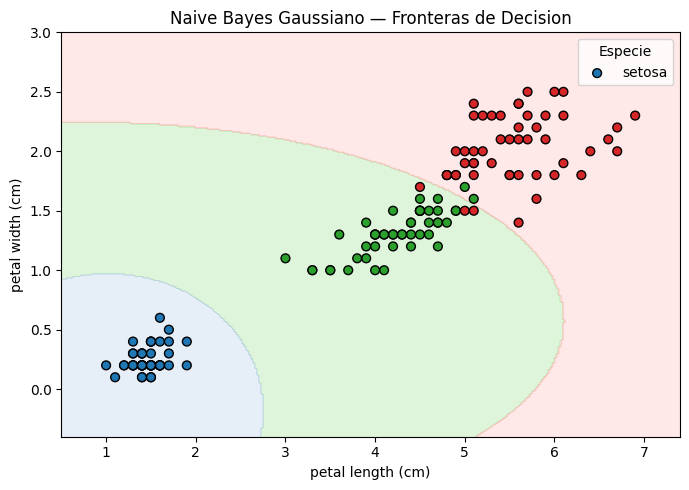

Las fronteras de NB son curvas suaves definidas por la superposicion
de distribuciones Gaussianas — no rectas como en la regresion logistica.


In [ ]:
from matplotlib.colors import ListedColormap
from sklearn.naive_bayes import GaussianNB
from sklearn.datasets import load_iris
import numpy as np, matplotlib.pyplot as plt

iris = load_iris()
X2 = iris.data[:, 2:4]  # largo y ancho del petalo
y  = iris.target

gnb2d = GaussianNB()
gnb2d.fit(X2, y)

x_min, x_max = X2[:,0].min()-0.5, X2[:,0].max()+0.5
y_min, y_max = X2[:,1].min()-0.5, X2[:,1].max()+0.5
xx, yy = np.meshgrid(np.linspace(x_min,x_max,300), np.linspace(y_min,y_max,300))
Z = gnb2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 5))
ax.contourf(xx, yy, Z, alpha=0.3,
            cmap=ListedColormap(["#AEC7E8","#98DF8A","#FFB3B3"]))
scatter = ax.scatter(X2[:,0], X2[:,1], c=y,
                     cmap=ListedColormap(["#1f77b4","#2ca02c","#d62728"]),
                     edgecolors='k', s=40)
ax.set_xlabel(iris.feature_names[2])
ax.set_ylabel(iris.feature_names[3])
ax.set_title('Naive Bayes Gaussiano — Fronteras de Decision')
ax.legend(*scatter.legend_elements(), title='Especie', labels=list(iris.target_names))
plt.tight_layout()
plt.show()

print("Las fronteras de NB son curvas suaves definidas por la superposicion")
print("de distribuciones Gaussianas — no rectas como en la regresion logistica.")

In [ ]:
# Inspeccionar parámetros aprendidos
print("Medias aprendidas por clase (µ) – Reflectancias espectrales:")
nombres_bandas = ['Azul', 'Verde', 'Rojo', 'NIR', 'SWIR1', 'SWIR2']
df_medias = pd.DataFrame(gnb.theta_, columns=nombres_bandas, index=nombres_clases)
print(df_medias.round(0))

Medias aprendidas por clase (µ) – Reflectancias espectrales:
                    Azul   Verde    Rojo     NIR   SWIR1   SWIR2
Agua               714.0   801.0   597.0   311.0   147.0   108.0
Bosque Amazónico   401.0   555.0   348.0  3762.0  1590.0   724.0
Cultivos           692.0   791.0   705.0  2593.0  2094.0  1100.0
Urbano            1198.0  1273.0  1401.0  1686.0  2389.0  2095.0
Pastizal/Puna      604.0   758.0   703.0  1501.0  1184.0   805.0


## 5. Velocidad vs. Exactitud: Comparación de Clasificadores

Benchmarkeamos en el dataset de cobertura forestal (54 características, 7 clases):

In [ ]:
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
import time

covtype = fetch_covtype()
rng = np.random.RandomState(42)
idx = rng.choice(len(covtype.data), size=10000, replace=False)
X_sub, y_sub = covtype.data[idx], covtype.target[idx]

X_tr, X_te, y_tr, y_te = train_test_split(X_sub, y_sub, test_size=0.25, random_state=42, stratify=y_sub)
esc = StandardScaler()
X_tr_e = esc.fit_transform(X_tr)
X_te_e = esc.transform(X_te)

clasificadores = {
    "Naive Bayes Gaussiano": GaussianNB(),
    "Regresión Logística":   LogisticRegression(max_iter=1000),
    "SVM (kernel RBF)":      SVC(kernel="rbf"),
}

resultados = {}
for nombre, clf in clasificadores.items():
    t0 = time.time()
    clf.fit(X_tr_e, y_tr)
    t_entrena = time.time() - t0

    t0 = time.time()
    y_pred_c = clf.predict(X_te_e)
    t_pred = time.time() - t0

    acc = accuracy_score(y_te, y_pred_c)
    resultados[nombre] = (t_entrena, t_pred, acc)

print(f"Dataset: Cobertura forestal (N = {len(X_sub)}, M = {X_sub.shape[1]}, 7 clases)")
print(f"\n{'Clasificador':<25}  {'Entren. (s)':>12}  {'Predict. (s)':>13}  {'Exactitud':>10}")
print("-" * 65)
for nombre, (tt, pt, acc) in resultados.items():
    print(f"{nombre:<25}  {tt:>12.4f}  {pt:>13.4f}  {acc:>10.2%}")

Dataset: Cobertura forestal (N = 10000, M = 54, 7 clases)

Clasificador                Entren. (s)   Predict. (s)   Exactitud
-----------------------------------------------------------------
Naive Bayes Gaussiano            0.0099         0.0053      14.12%
Regresión Logística              1.9667         0.0033      72.96%
SVM (kernel RBF)                 3.2142         1.1499      74.08%


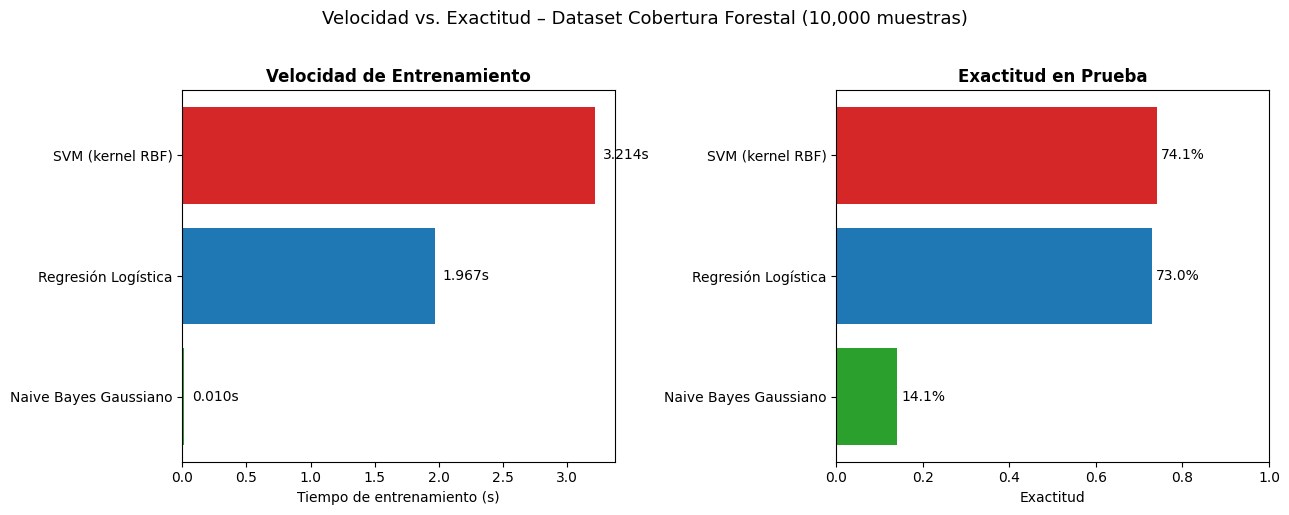


Conclusiones:
  - Naive Bayes: Extremadamente rápido (~100x más que SVM), buena línea base
  - SVM RBF: Más lento pero más exacto; captura fronteras no lineales
  - Regresión Logística: Equilibrio entre velocidad y exactitud


In [ ]:
# Visualizar la comparación
nombres_clf = list(resultados.keys())
tiempos_entrena = [resultados[n][0] for n in nombres_clf]
exactitudes     = [resultados[n][2] for n in nombres_clf]

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
colores = ['#2ca02c', '#1f77b4', '#d62728']

ejes[0].barh(nombres_clf, tiempos_entrena, color=colores)
ejes[0].set_xlabel('Tiempo de entrenamiento (s)')
ejes[0].set_title('Velocidad de Entrenamiento', fontweight='bold')
for i, v in enumerate(tiempos_entrena):
    ejes[0].text(v + max(tiempos_entrena)*0.02, i, f'{v:.3f}s', va='center', fontsize=10)

ejes[1].barh(nombres_clf, exactitudes, color=colores)
ejes[1].set_xlabel('Exactitud')
ejes[1].set_title('Exactitud en Prueba', fontweight='bold')
ejes[1].set_xlim(0, 1)
for i, v in enumerate(exactitudes):
    ejes[1].text(v + 0.01, i, f'{v:.1%}', va='center', fontsize=10)

plt.suptitle('Velocidad vs. Exactitud – Dataset Cobertura Forestal (10,000 muestras)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print("\nConclusiones:")
print("  - Naive Bayes: Extremadamente rápido (~100x más que SVM), buena línea base")
print("  - SVM RBF: Más lento pero más exacto; captura fronteras no lineales")
print("  - Regresión Logística: Equilibrio entre velocidad y exactitud")

---
## 🔬 Ejercicio: Clasificar Calidad del Aire en Lima

Usando el conjunto de datos sintéticos de contaminantes del aire en Lima (inspirado en datos SENAMHI/OEFA):

1. Entrena un clasificador **Naive Bayes Gaussiano** para predecir si el ICA (Índice de Calidad del Aire) es "Bueno", "Moderado" o "Malo"
2. Visualiza la matriz de confusión
3. ¿Qué contaminante es el mejor indicador de mala calidad del aire según las medias aprendidas?

In [ ]:
# Dataset sintético de calidad del aire en Lima
np.random.seed(42)
n_dias = 365 * 3  # 3 años de datos

# Contaminantes en µg/m³
pm25_bueno    = np.random.normal(8, 3, n_dias // 3)
pm25_moderado = np.random.normal(25, 8, n_dias // 3)
pm25_malo     = np.random.normal(65, 20, n_dias // 3)

no2_bueno    = np.random.normal(20, 8, n_dias // 3)
no2_moderado = np.random.normal(60, 15, n_dias // 3)
no2_malo     = np.random.normal(120, 30, n_dias // 3)

o3_bueno    = np.random.normal(40, 10, n_dias // 3)
o3_moderado = np.random.normal(80, 20, n_dias // 3)
o3_malo     = np.random.normal(150, 40, n_dias // 3)

X_aire = np.vstack([
    np.column_stack([pm25_bueno, no2_bueno, o3_bueno]),
    np.column_stack([pm25_moderado, no2_moderado, o3_moderado]),
    np.column_stack([pm25_malo, no2_malo, o3_malo])
])
X_aire = np.maximum(X_aire, 0)  # No valores negativos
y_aire = np.array([0]*(n_dias//3) + [1]*(n_dias//3) + [2]*(n_dias//3))
nombres_ica = ['Bueno', 'Moderado', 'Malo']

# --- Tu código aquí ---
# X_tr_aire, X_te_aire, y_tr_aire, y_te_aire = train_test_split(...)
# gnb_aire = GaussianNB()
# gnb_aire.fit(...)
# y_pred_aire = gnb_aire.predict(...)
# print(metrics.classification_report(...))

print("Dataset de calidad del aire creado:")
print(f"  Muestras: {len(X_aire)}")
print(f"  Características: PM2.5 (µg/m³), NO₂ (µg/m³), O₃ (µg/m³)")
print(f"  Clases: Bueno={n_dias//3}, Moderado={n_dias//3}, Malo={n_dias//3}")

Dataset de calidad del aire creado:
  Muestras: 1095
  Características: PM2.5 (µg/m³), NO₂ (µg/m³), O₃ (µg/m³)
  Clases: Bueno=365, Moderado=365, Malo=365


Exactitud: 99.27%
              precision    recall  f1-score   support

       Bueno       1.00      1.00      1.00        91
    Moderado       0.98      1.00      0.99        91
        Malo       1.00      0.98      0.99        92

    accuracy                           0.99       274
   macro avg       0.99      0.99      0.99       274
weighted avg       0.99      0.99      0.99       274


Medias aprendidas por clase:
          PM2.5    NO₂     O₃
Bueno       8.0   20.5   40.6
Moderado   25.0   60.8   79.6
Malo       66.4  120.6  150.4


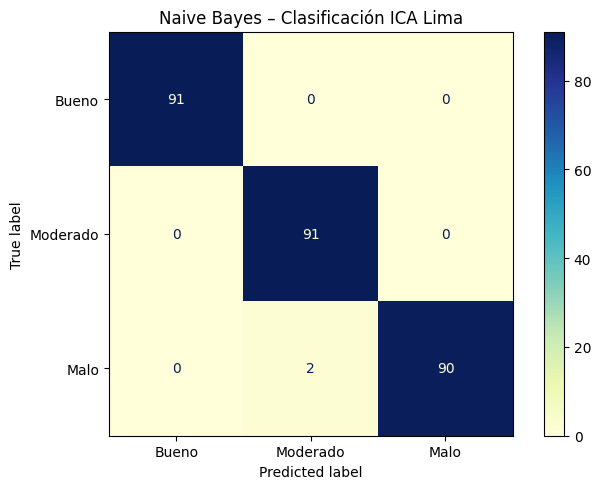

In [ ]:
# Solución
from sklearn.metrics import ConfusionMatrixDisplay

X_tr_a, X_te_a, y_tr_a, y_te_a = train_test_split(
    X_aire, y_aire, test_size=0.25, random_state=42, stratify=y_aire
)

gnb_aire = GaussianNB()
gnb_aire.fit(X_tr_a, y_tr_a)
y_pred_a = gnb_aire.predict(X_te_a)

print(f"Exactitud: {metrics.accuracy_score(y_te_a, y_pred_a):.2%}")
print(metrics.classification_report(y_te_a, y_pred_a, target_names=nombres_ica))

# Medias aprendidas
print("\nMedias aprendidas por clase:")
cols = ['PM2.5', 'NO₂', 'O₃']
df_medias_aire = pd.DataFrame(gnb_aire.theta_, columns=cols, index=nombres_ica)
print(df_medias_aire.round(1))

# Matriz de confusión
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(y_te_a, y_pred_a, display_labels=nombres_ica,
                                         cmap='YlGnBu', ax=ax)
ax.set_title('Naive Bayes – Clasificación ICA Lima')
plt.tight_layout()
plt.show()

---
## 9. Cuando Usar Naive Bayes

| Fortalezas | Limitaciones |
|---|---|
| Entrenamiento y predicción extremadamente rápidos | Asume independencia de características (rara vez es cierto) |
| Funciona bien con conjuntos de entrenamiento pequeños | Las estimaciones de probabilidad pueden estar mal calibradas |
| Maneja datos de alta dimensión de forma natural | Las características continuas deben seguir aproximadamente la distribución asumida |
| No requiere ajuste de hiperparámetros (NB gaussiano) | A menudo, modelos más flexibles lo superan en conjuntos de datos grandes |
| Buena base para cualquier tarea de clasificación | No puede capturar interacciones entre características |

### Directrices practicas para datos ambientales peruanos
### Pautas prácticas

- **Siempre prueba primero el modelo NB** como referencia: solo toma unos segundos y te da un punto de referencia para comparar.

- **NB destaca** cuando tienes datos de entrenamiento limitados, muchas características o necesitas predicciones muy rápidas (por ejemplo, clasificación de sensores en tiempo real).

- **NB tiene dificultades** cuando las interacciones entre características son importantes (por ejemplo, una especie solo está presente cuando *tanto* la temperatura como la precipitación se encuentran dentro de ciertos rangos, o estrés hídrico requiere combinar temperatura Y precipitación).

- Si NB tiene un rendimiento casi tan bueno como un modelo complejo, es preferible: es más simple, más rápido y menos propenso al sobreajuste.



---
## Resumen

| Concepto | Conclusión clave |
|----------|------------------|
| Teorema de Bayes | $P(c \mid \mathbf{x}) \propto P(\mathbf{x} \mid c) \cdot P(c)$ |
| Supuesto naive | Las características son condicionalmente independientes dado la clase |
| Naive Bayes Gaussiano | Modela cada característica como una distribución normal por clase; entrenamiento = calcular medias y varianzas |
| Multinomial / Bernoulli NB | Para características de conteo y binarias respectivamente |
| Velocidad | Entrenamiento es $O(N \cdot M)$ — casi instantáneo incluso con grandes datasets |
| Mejor caso de uso | Línea base rápida, datasets pequeños de entrenamiento, datos de alta dimensión |
| `scikit-learn` | `GaussianNB()`, `MultinomialNB()`, `BernoulliNB()` |